# 実験結果の解析

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path.cwd().resolve()
if not (project_dir / "configs").is_dir():
    project_dir = project_dir.parent
experiment_name = "exp_v3_grid_search"
experiment_dir = project_dir / "data" / experiment_name
required_files = ["config_used.json", "raw_data.csv", "summary_data.csv"]
if any(not (experiment_dir / name).is_file() for name in required_files):
    raise FileNotFoundError(f"実験を先に実行してください: {experiment_dir}")
with (experiment_dir / "config_used.json").open(encoding="utf-8") as file:
    config = json.load(file)
raw_df = pd.read_csv(experiment_dir / "raw_data.csv")
summary_df = pd.read_csv(experiment_dir / "summary_data.csv")
config


{'experiment_name': 'exp_v3_grid_search',
 'agent_class': 'AgentV3',
 'field_class': 'FieldV3',
 'simulation': {'total_steps': 200000,
  'eval_start_step': 100001,
  'num_runs': 1,
  'base_seed': 43,
  'workers': 5},
 'grid_parameters': {'death_threshold': [-30],
  'mutation_rate': [0.05],
  'transfer_amount': [5]},
 'fixed_field_parameters': {'field_size': 10,
  'initial_agents': 20,
  'initial_food_prob': 0.1,
  'step_food_prob': 0.003,
  'food_durability': 5.0,
  'energy_loss_per_step': 0.1,
  'reward_food': 1.0,
  'clone_threshold': 100.0}}

In [2]:
time_series_path = experiment_dir / "time_series_data.csv"
time_series_df = None
if time_series_path.is_file():
    time_series_df = pd.read_csv(time_series_path)
    if time_series_df.empty:
        print("時系列データは空です。1000step以上の実験を実行してください。")
    else:
        display(time_series_df)
else:
    print("時系列データがありません。実験を再実行して time_series_data.csv を作成してください。")

,death_threshold,mutation_rate,transfer_amount,run_id,seed,step,population,altruism_count
0,-30,0.05,5,0,43,101000,14,6264
1,-30,0.05,5,0,43,102000,15,6606
2,-30,0.05,5,0,43,103000,16,7218
3,-30,0.05,5,0,43,104000,14,7371
4,-30,0.05,5,0,43,105000,14,6169
...,...,...,...,...,...,...,...,...
95,-30,0.05,5,0,43,196000,15,5649
96,-30,0.05,5,0,43,197000,15,5608
97,-30,0.05,5,0,43,198000,14,5329
98,-30,0.05,5,0,43,199000,12,4372


,death_threshold,mutation_rate,transfer_amount,run_id,seed,step,population,altruism_count
0,-30,0.05,5,0,43,101000,14,6264
1,-30,0.05,5,0,43,102000,15,6606
2,-30,0.05,5,0,43,103000,16,7218
3,-30,0.05,5,0,43,104000,14,7371
4,-30,0.05,5,0,43,105000,14,6169
...,...,...,...,...,...,...,...,...
95,-30,0.05,5,0,43,196000,15,5649
96,-30,0.05,5,0,43,197000,15,5608
97,-30,0.05,5,0,43,198000,14,5329
98,-30,0.05,5,0,43,199000,12,4372


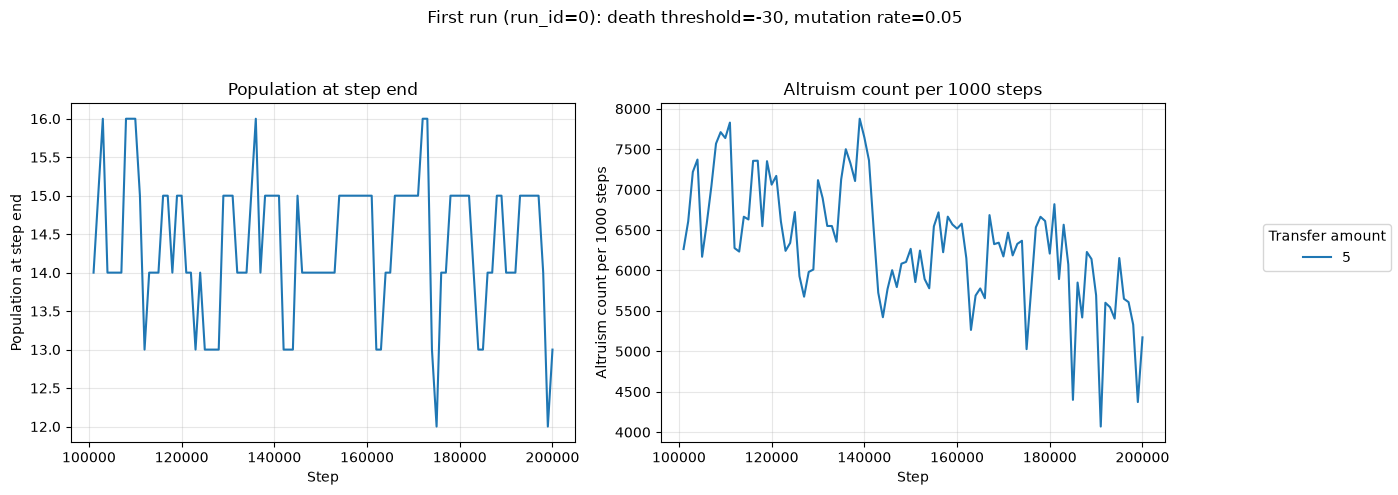

In [3]:
if time_series_df is not None and not time_series_df.empty:
    # 比較したい値に変更してください。
    selected_death_threshold = time_series_df["death_threshold"].min()
    selected_mutation_rate = time_series_df["mutation_rate"].min()

    selected_time_series = time_series_df.loc[
        (time_series_df["death_threshold"] == selected_death_threshold)
        & (time_series_df["mutation_rate"] == selected_mutation_rate)
    ]
    if selected_time_series.empty:
        print("選択した条件の時系列データがありません。")
    else:
        display(selected_time_series)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
        for transfer_amount, transfer_df in selected_time_series.groupby("transfer_amount", sort=True):
            transfer_df = transfer_df.sort_values("step")
            for metric, axis in zip(["population", "altruism_count"], axes):
                axis.plot(transfer_df["step"], transfer_df[metric], label=f"{transfer_amount:g}")
        for label, axis in zip(["Population at step end", "Altruism count per 1000 steps"], axes):
            axis.set_title(label)
            axis.set_xlabel("Step")
            axis.set_ylabel(label)
            axis.grid(True, alpha=0.3)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, title="Transfer amount", loc="center right")
        fig.suptitle(
            f"First run (run_id=0): death threshold={selected_death_threshold:g}, "
            f"mutation rate={selected_mutation_rate:g}"
        )
        fig.tight_layout(rect=(0, 0, 0.85, 0.93))
        plt.show()


In [4]:
display(raw_df.head())
raw_df.describe()


,run_id,seed,avg_population,std_population,avg_altruism_count,std_altruism_count,death_threshold,mutation_rate,transfer_amount
0,0,43,14.36023,0.939443,6.33023,2.492232,-30,0.05,5


,run_id,seed,avg_population,std_population,avg_altruism_count,std_altruism_count,death_threshold,mutation_rate,transfer_amount
count,1.0,1.0,1.00000,1.000000,1.00000,1.000000,1.0,1.00,1.0
mean,0.0,43.0,14.36023,0.939443,6.33023,2.492232,-30.0,0.05,5.0
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.0,43.0,14.36023,0.939443,6.33023,2.492232,-30.0,0.05,5.0
25%,0.0,43.0,14.36023,0.939443,6.33023,2.492232,-30.0,0.05,5.0
50%,0.0,43.0,14.36023,0.939443,6.33023,2.492232,-30.0,0.05,5.0
75%,0.0,43.0,14.36023,0.939443,6.33023,2.492232,-30.0,0.05,5.0
max,0.0,43.0,14.36023,0.939443,6.33023,2.492232,-30.0,0.05,5.0


## 過半数が利他行動をした step 数のヒートマップ

各条件5試行し、各試行の最後の10,000 step（190,001〜200,000）で、
行動参加個体の50%超が正の量を譲渡した step の総数。

```bash
python -m scripts.simu_heatmap --config configs/exp_v3_heatmap.json
```


,death_threshold,transfer_amount,num_runs,avg_majority_steps,std_majority_steps
0,-200,2,10,236.4,342.181628
1,-200,4,10,108.5,131.669831
2,-200,6,10,107.8,96.354438
3,-200,8,10,49.7,35.969277
4,-200,10,10,55.6,45.925544
...,...,...,...,...,...
95,-10,2,10,99.2,166.728522
96,-10,4,10,40.6,101.613866
97,-10,6,10,36.6,58.939140
98,-10,8,10,21.4,52.491692


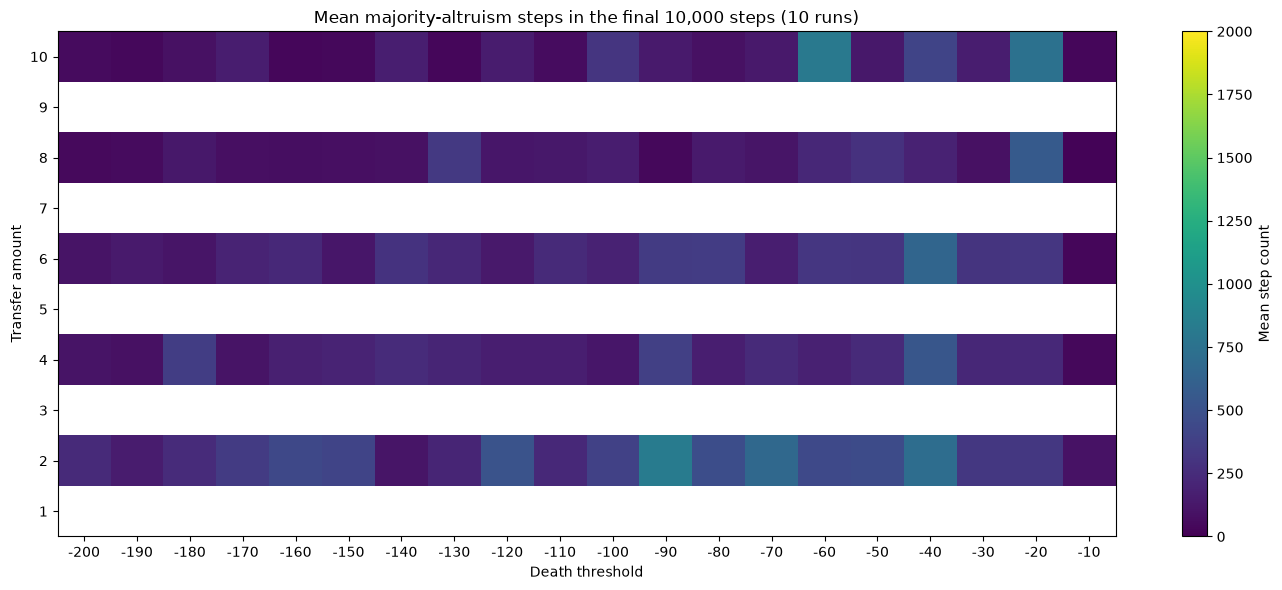

In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

heatmap_project_dir = Path.cwd().resolve()
if not (heatmap_project_dir / "configs").is_dir():
    heatmap_project_dir = heatmap_project_dir.parent
heatmap_summary_path = heatmap_project_dir / "data" / "exp_v3_heatmap" / "summary_data.csv"

if not heatmap_summary_path.is_file():
    print("ヒートマップ用データがありません。プロジェクト直下で実行してください：")
    print("python -m scripts.simu_heatmap --config configs/exp_v3_heatmap.json")
else:
    heatmap_summary_df = pd.read_csv(heatmap_summary_path)
    display(heatmap_summary_df)
    heatmap_values = heatmap_summary_df.pivot(
        index="transfer_amount", columns="death_threshold", values="avg_majority_steps"
    ).reindex(index=range(1, 11), columns=range(-200, 0, 10))
    fig, ax = plt.subplots(figsize=(14, 6))
    heatmap_image = ax.imshow(
        heatmap_values.to_numpy(), origin="lower", aspect="auto",
        cmap="viridis", vmin=0, vmax=2000,
    )
    ax.set_xticks(range(len(heatmap_values.columns)), labels=heatmap_values.columns)
    ax.set_yticks(range(len(heatmap_values.index)), labels=heatmap_values.index)
    ax.set_xlabel("Death threshold")
    ax.set_ylabel("Transfer amount")
    ax.set_title("Mean majority-altruism steps in the final 10,000 steps (10 runs)")
    fig.colorbar(heatmap_image, ax=ax, label="Mean step count")
    fig.tight_layout()
    plt.show()
